# 07 — ResNet18 + BiLSTM Text Encoder | PathVQA

**Fifth baseline for the QTAF-Net capstone.** All model weights are randomly initialized and learned from scratch. **No pretrained weights or pretrained embeddings.**

This notebook performs **two training stages**: (1) original training, (2) fine-tuning of its own best checkpoint. Validation uses **ground-truth (oracle) answer-type routing**, as in the existing baselines. The test set remains untouched for the shared final evaluation notebook.

Architecture: ResNet18 visual backbone (512-dimensional global features) + trainable 128-dimensional word embeddings + BiLSTM (128 hidden per direction, 256-dimensional text features) → concatenation → 256-dimensional fusion MLP → two answer heads (2 yes/no classes, 1,000 open classes).

**Submission and execution notes.** Run this notebook top-to-bottom in Kaggle with a GPU and Internet enabled. Install `datasets` using the first code cell; other imports include PyTorch, torchvision, Hugging Face datasets, NumPy, pandas, PIL, and Matplotlib. Attach the earlier `late_fusion_latest.pth` checkpoint so the training-only vocabularies match the previous experiments. Training produces new ResNet18 checkpoints; the notebook does not load pretrained ResNet18 weights. Existing saved outputs are from a previous execution and have not been regenerated here.

## 1. Kaggle setup

Enable a GPU. Add the PathVQA dataset through Hugging Face internet access. Attach **exactly one** `late_fusion_latest.pth` to Kaggle Input for the **vocabulary mappings only**. This notebook never loads its trained model weights. The first run may require internet access to install `datasets` and fetch PathVQA.

In [10]:
# Install the dataset library and initialize the reproducible Kaggle environment.
!pip -q install datasets

import os, re, glob, hashlib, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
from torchvision.models import resnet18


Device: cuda


## 2. Load PathVQA and remove image overlap

Use the identical train/validation image-hash cleaning as previous experiments. Keep test held out.

In [ ]:
# Load the dataset and exclude training images duplicated in validation.
dataset = load_dataset("flaviagiammarino/path-vqa")
for split in ("train", "validation", "test"):
    print(split, len(dataset[split]))

def image_hash(image):
    image = image.convert("RGB")
    h = hashlib.sha256()
    h.update(str(image.size).encode())
    h.update(image.tobytes())
    return h.hexdigest()

val_hashes = {image_hash(s["image"]) for s in tqdm(dataset["validation"], desc="Hash validation")}
keep_indices = [
    i for i, s in enumerate(tqdm(dataset["train"], desc="Check training overlap"))
    if image_hash(s["image"]) not in val_hashes
]
clean_train = dataset["train"].select(keep_indices)
clean_val = dataset["validation"]
clean_test = dataset["test"]  # held out
print("Clean train:", len(clean_train), "Validation:", len(clean_val))
assert len(clean_train) == 19648, "Unexpected cleaning count; inspect dataset version."

README.md:   0%|          | 0.00/4.29k [00:00<?, ?B/s]

data/train-00000-of-00007-f2d0e9ef9f022d(…): reconstructing file:   0%|          |  0.00B / 42.8MB            

data/train-00000-of-00007-f2d0e9ef9f022d(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-47d8e0220bf6c9(…): reconstructing file:   0%|          |  0.00B / 81.0MB            

data/train-00001-of-00007-47d8e0220bf6c9(…): downloading bytes:           |  0.00B            

data/train-00002-of-00007-7fb5037c4c5da7(…): reconstructing file:   0%|          |  0.00B /  104MB            

... (24 outputs left out)

train 19654
validation 6259
test 6719


Hash validation:   0%|          | 0/6259 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Check training overlap:   0%|          | 0/19654 [00:00<?, ?it/s]

## 3. Restore the exact training-only vocabularies

Only `word2idx` and `open_answer2idx` are read from the earlier checkpoint; **no trained parameters** are reused.

In [11]:
# Reuse the original training vocabulary and answer classes for a fair baseline comparison.
candidates = sorted(
    glob.glob("/kaggle/input/**/late_fusion_latest.pth", recursive=True)
    + glob.glob("/kaggle/working/late_fusion_latest.pth")
)
for i, path in enumerate(candidates):
    print(i, path)
if len(candidates) != 1:
    raise RuntimeError("Attach exactly one original late_fusion_latest.pth checkpoint.")
# Load only checkpoints you created and trust.
saved = torch.load(candidates[0], map_location="cpu", weights_only=False)
word2idx = saved["word2idx"]
open_answer2idx = saved["open_answer2idx"]
del saved
assert len(open_answer2idx) == 1000
assert word2idx["<PAD>"] == 0 and word2idx["<UNK>"] == 1
print("Question vocabulary:", len(word2idx))
print("Open answer vocabulary:", len(open_answer2idx))

0 /kaggle/input/datasets/dollarwala/cnn-bilstm/late_fusion_latest.pth
Question vocabulary: 3972
Open answer vocabulary: 1000


## 4. Encode questions and answers

Match the previous regex tokenization, maximum length 32, and 1,000 open-answer vocabulary. Unseen validation open answers count as incorrect.

In [12]:
# Convert questions to padded token IDs and encode the correct answer category.
MAX_QUESTION_LENGTH = 32

def encode_question(text):
    tokens = re.findall(r"\w+|[^\w\s]", str(text).lower().strip())
    ids = [word2idx.get(token, word2idx["<UNK>"]) for token in tokens[:MAX_QUESTION_LENGTH]]
    return ids + [word2idx["<PAD>"]] * (MAX_QUESTION_LENGTH - len(ids))

def encode_answer(answer):
    answer = str(answer).lower().strip()
    if answer == "no": return 0, 0
    if answer == "yes": return 0, 1
    return 1, open_answer2idx.get(answer, -1)

open_total = open_covered = 0
for answer in clean_val["answer"]:
    kind, label = encode_answer(answer)
    if kind == 1:
        open_total += 1
        open_covered += int(label >= 0)
print(f"Open-answer coverage: {open_covered}/{open_total} = {open_covered/open_total:.2%}")

Open-answer coverage: 2086/3134 = 66.56%


## 5. Image preprocessing

Match the earlier baselines: preserve aspect ratio, white-pad to 224×224, float32 RGB in [0, 1]. **No ImageNet mean/std normalization** is introduced.

In [13]:
# Resize and white-pad RGB pathology images without pretrained-model normalization.
IMAGE_SIZE = 224

def preprocess_image(image):
    image = image.convert("RGB")
    image = ImageOps.contain(image, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.BILINEAR)
    background = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (255, 255, 255))
    background.paste(image, ((IMAGE_SIZE - image.width)//2, (IMAGE_SIZE - image.height)//2))
    array = np.asarray(background, dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1)

print("Image tensor:", preprocess_image(clean_train[0]["image"]).shape)

Image tensor: torch.Size([3, 224, 224])


## 6. Dataset and DataLoaders

Both image and question are used as model inputs. True answer type is supplied only for selecting the supervised head during training and for oracle-routed validation.

In [14]:
# Create paired image-question batches and separate training/validation loaders.
class PathVQAResNetDataset(Dataset):
    def __init__(self, hf_split):
        self.data = hf_split
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        example = self.data[idx]
        answer_type, answer_label = encode_answer(example["answer"])
        return {
            "image": preprocess_image(example["image"]),
            "question": torch.tensor(encode_question(example["question"]), dtype=torch.long),
            "answer_type": torch.tensor(answer_type, dtype=torch.long),
            "answer_label": torch.tensor(answer_label, dtype=torch.long),
        }

train_dataset = PathVQAResNetDataset(clean_train)
val_dataset = PathVQAResNetDataset(clean_val)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2,
                          pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2,
                        pin_memory=torch.cuda.is_available())
batch = next(iter(train_loader))
for k, v in batch.items(): print(k, tuple(v.shape))
print("Train batches:", len(train_loader), "Validation batches:", len(val_loader))

image (32, 3, 224, 224)
question (32, 32)
answer_type (32,)
answer_label (32,)
Train batches: 614 Validation batches: 196


## 7. ResNet18 + BiLSTM architecture (from scratch)

`resnet18(weights=None)` ensures no pretrained ImageNet weights are loaded. We retain its standard residual blocks and replace the 1,000-class classifier with an identity layer to extract 512-dimensional visual features. The question embedding and BiLSTM are also randomly initialized. This is **late feature fusion**, not a question-guided attention network.

In [15]:
# Build a randomly initialized ResNet18 image encoder and BiLSTM question encoder.
class ResNet18ImageEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(weights=None)  # CRITICAL: random initialization; no pretrained weights
        self.backbone.fc = nn.Identity()         # [B, 512]

    def forward(self, images):
        return self.backbone(images)

class QuestionEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)

    def forward(self, questions):
        embeddings = self.embedding(questions)
        lengths = (questions != 0).sum(dim=1).clamp(min=1)
        packed = nn.utils.rnn.pack_padded_sequence(
            embeddings, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        return torch.cat([hidden[-2], hidden[-1]], dim=1)  # [B, 256]

class ResNet18BiLSTMBaseline(nn.Module):
    def __init__(self, vocab_size, num_open_answers=1000):
        super().__init__()
        self.image_encoder = ResNet18ImageEncoder()
        self.question_encoder = QuestionEncoder(vocab_size)
        self.fusion = nn.Sequential(
            nn.Linear(512 + 256, 256), nn.ReLU(), nn.Dropout(0.3)
        )
        self.yes_no_head = nn.Linear(256, 2)
        self.open_head = nn.Linear(256, num_open_answers)

    def forward(self, images, questions):
        image_features = self.image_encoder(images)
        question_features = self.question_encoder(questions)
        fused = self.fusion(torch.cat([image_features, question_features], dim=1))
        return self.yes_no_head(fused), self.open_head(fused)

model = ResNet18BiLSTMBaseline(len(word2idx), len(open_answer2idx)).to(device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Trainable parameters: 12403498


## 8. Check model output shapes

Confirm that the two heads predict 2 yes/no labels and 1,000 open-answer labels.

In [16]:
# Check the output dimensions of the closed and open answer heads.
model.eval()
with torch.no_grad():
    yn, op = model(batch['image'][:2].to(device), batch['question'][:2].to(device))
print('Yes/no:', tuple(yn.shape), 'Open:', tuple(op.shape))
assert tuple(yn.shape) == (2, 2)
assert tuple(op.shape) == (2, 1000)
print('ResNet18 pretrained weights: NONE (weights=None)')


Yes/no: (2, 2) Open: (2, 1000)
ResNet18 pretrained weights: NONE (weights=None)


## 9. Loss and validation

The closed and covered-open cross-entropy losses are averaged when both are present. Unseen open-answer labels (`-1`) are excluded from training loss, but counted as incorrect at validation. Validation uses oracle answer-type routing for comparability with earlier baselines. Accuracy values are fractions (0–1).

In [17]:
# Calculate type-specific classification loss and validation exact-match accuracy.
def compute_loss(yes_no_logits, open_logits, types, labels):
    closed = types == 0
    open_valid = (types == 1) & (labels >= 0)
    losses = []
    if closed.any():
        losses.append(F.cross_entropy(yes_no_logits[closed], labels[closed]))
    if open_valid.any():
        losses.append(F.cross_entropy(open_logits[open_valid], labels[open_valid]))
    if not losses:
        return (yes_no_logits.sum() + open_logits.sum()) * 0
    return sum(losses) / len(losses)

def train_one_epoch(model, loader, optimizer, device):
    model.train()
    loss_sum = count = 0
    for batch in tqdm(loader, desc="Training"):
        images = batch["image"].to(device, non_blocking=True)
        questions = batch["question"].to(device, non_blocking=True)
        types = batch["answer_type"].to(device)
        labels = batch["answer_label"].to(device)
        optimizer.zero_grad()
        yn, op = model(images, questions)
        loss = compute_loss(yn, op, types, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        size = images.shape[0]
        loss_sum += loss.item() * size
        count += size
    return loss_sum / count

@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    closed_correct = closed_total = open_correct = open_total = 0
    for batch in tqdm(loader, desc="Validation"):
        images = batch["image"].to(device, non_blocking=True)
        questions = batch["question"].to(device, non_blocking=True)
        types = batch["answer_type"].to(device)
        labels = batch["answer_label"].to(device)
        yn, op = model(images, questions)
        closed = types == 0
        opened = types == 1
        closed_correct += ((yn.argmax(1) == labels) & closed).sum().item()
        open_correct += ((op.argmax(1) == labels) & opened).sum().item()
        closed_total += closed.sum().item()
        open_total += opened.sum().item()
    return {
        "overall_accuracy": (closed_correct + open_correct) / max(closed_total + open_total, 1),
        "closed_accuracy": closed_correct / max(closed_total, 1),
        "open_accuracy": open_correct / max(open_total, 1),
    }
print("Loss, training, validation functions ready.")

Loss, training, validation functions ready.


## 10. Original training — up to 30 epochs

Adam learning rate 0.001, weight decay 1e-5, batch size 32, gradient clipping 1.0, early-stopping patience 5. Save best weights separately from the latest resume checkpoint.

In [18]:
# Train from scratch with early stopping and save the best validation checkpoint.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
MAX_EPOCHS = 30
PATIENCE = 5
best_accuracy, best_epoch, no_improvement = -1.0, 0, 0
history = []

best_path = "/kaggle/working/best_resnet18_bilstm.pth"
latest_path = "/kaggle/working/resnet18_bilstm_latest.pth"
history_path = "/kaggle/working/resnet18_bilstm_history.csv"

for epoch in range(1, MAX_EPOCHS + 1):
    loss = train_one_epoch(model, train_loader, optimizer, device)
    metrics = validate(model, val_loader, device)
    overall = metrics["overall_accuracy"]
    history.append({
        "epoch": epoch, "train_loss": loss, "overall_accuracy": overall,
        "yes_no_accuracy": metrics["closed_accuracy"], "open_accuracy": metrics["open_accuracy"]
    })
    print(f"Epoch {epoch:02d} | Loss: {loss:.4f} | Overall: {overall:.2%} | "
          f"Yes/No: {metrics['closed_accuracy']:.2%} | Open: {metrics['open_accuracy']:.2%}")
    if overall > best_accuracy:
        best_accuracy, best_epoch, no_improvement = overall, epoch, 0
        torch.save(model.state_dict(), best_path)
        print("New best ResNet18+BiLSTM saved!")
    else:
        no_improvement += 1
    torch.save({
        "epoch": epoch, "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(), "history": history,
        "best_accuracy": best_accuracy, "best_epoch": best_epoch,
        "word2idx": word2idx, "open_answer2idx": open_answer2idx,
        "model_name": "ResNet18_BiLSTM_scratch"
    }, latest_path)
    pd.DataFrame(history).to_csv(history_path, index=False)
    if no_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("Best original ResNet18+BiLSTM epoch:", best_epoch)
print(f"Best original ResNet18+BiLSTM accuracy: {best_accuracy:.2%}")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch 01 | Loss: 2.6687 | Overall: 44.83% | Yes/No: 81.06% | Open: 8.71%
New best ResNet18+BiLSTM saved!


Training:   0%|          | 0/614 [00:00<?, ?it/s]

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ba491ffe7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ba491ffe7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (96 outputs left out)

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ba491ffe7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ba491ffe7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 30 | Loss: 1.0149 | Overall: 51.61% | Yes/No: 85.28% | Open: 18.03%
Best original ResNet18+BiLSTM epoch: 29
Best original ResNet18+BiLSTM accuracy: 52.61%


## 11. Evaluate best original checkpoint

Reload best weights (not final epoch) and report overall, yes/no, and open-ended validation accuracy.

In [19]:
# Restore the best original checkpoint before reporting validation metrics.
original_candidates = (
    glob.glob("/kaggle/working/best_resnet18_bilstm.pth")
    + glob.glob("/kaggle/input/**/best_resnet18_bilstm.pth", recursive=True)
)
if not original_candidates:
    raise FileNotFoundError("Train ResNet18 + BiLSTM or attach best_resnet18_bilstm.pth.")
original_best_checkpoint = original_candidates[0]
model.load_state_dict(torch.load(original_best_checkpoint, map_location=device, weights_only=True))
original_metrics = validate(model, val_loader, device)
print("BEST ORIGINAL ResNet18 + BiLSTM")
print(f"Overall: {original_metrics['overall_accuracy']:.2%}")
print(f"Yes/No: {original_metrics['closed_accuracy']:.2%}")
print(f"Open: {original_metrics['open_accuracy']:.2%}")
print("Checkpoint:", original_best_checkpoint)

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

BEST ORIGINAL ResNet18 + BiLSTM
Overall: 52.61%
Yes/No: 85.98%
Open: 19.34%
Checkpoint: /kaggle/working/best_resnet18_bilstm.pth


## 12. Fine-tuning — up to 10 additional epochs

Continue **only from your own best original ResNet18 checkpoint** with fresh Adam optimizer, learning rate 0.0001, weight decay 1e-5, and patience 3. This is fine-tuning of a scratch-trained model, not pretrained transfer learning.

In [20]:
# Continue training from the best original weights with a reduced learning rate.
model.load_state_dict(torch.load(original_best_checkpoint, map_location=device, weights_only=True))
optimizer_ft = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)
FT_EPOCHS, FT_PATIENCE = 10, 3
best_ft_accuracy, best_ft_epoch, ft_no_improvement = -1.0, 0, 0
ft_history = []

ft_best_path = "/kaggle/working/best_resnet18_bilstm_finetuned.pth"
ft_latest_path = "/kaggle/working/resnet18_bilstm_finetune_latest.pth"
ft_history_path = "/kaggle/working/resnet18_bilstm_finetune_history.csv"

for epoch in range(1, FT_EPOCHS + 1):
    loss = train_one_epoch(model, train_loader, optimizer_ft, device)
    metrics = validate(model, val_loader, device)
    overall = metrics["overall_accuracy"]
    ft_history.append({
        "finetune_epoch": epoch, "train_loss": loss,
        "overall_accuracy": overall, "yes_no_accuracy": metrics["closed_accuracy"],
        "open_accuracy": metrics["open_accuracy"]
    })
    print(f"Fine-tune epoch {epoch:02d} | Loss: {loss:.4f} | Overall: {overall:.2%} | "
          f"Yes/No: {metrics['closed_accuracy']:.2%} | Open: {metrics['open_accuracy']:.2%}")
    if overall > best_ft_accuracy:
        best_ft_accuracy, best_ft_epoch, ft_no_improvement = overall, epoch, 0
        torch.save(model.state_dict(), ft_best_path)
        print("New best fine-tuned ResNet18+BiLSTM saved!")
    else:
        ft_no_improvement += 1
    torch.save({
        "finetune_epoch": epoch, "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer_ft.state_dict(), "history": ft_history,
        "best_accuracy": best_ft_accuracy, "best_epoch": best_ft_epoch,
        "word2idx": word2idx, "open_answer2idx": open_answer2idx,
        "model_name": "ResNet18_BiLSTM_scratch_finetuned", "initial_checkpoint": original_best_checkpoint
    }, ft_latest_path)
    pd.DataFrame(ft_history).to_csv(ft_history_path, index=False)
    if ft_no_improvement >= FT_PATIENCE:
        print("Fine-tuning early stopping triggered.")
        break

print("Best additional fine-tuning epoch:", best_ft_epoch)
print(f"Best fine-tuned ResNet18+BiLSTM accuracy: {best_ft_accuracy:.2%}")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ba491ffe7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ba491ffe7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Fine-tune epoch 01 | Loss: 0.9247 | Overall: 53.35% | Yes/No: 86.02% | Open: 20.77%
New best fine-tuned ResNet18+BiLSTM saved!


Training:   0%|          | 0/614 [00:00<?, ?it/s]

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

... (12 outputs left out)

Fine-tune epoch 05 | Loss: 0.8272 | Overall: 53.65% | Yes/No: 86.37% | Open: 21.03%


Training:   0%|          | 0/614 [00:00<?, ?it/s]

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Fine-tune epoch 06 | Loss: 0.8107 | Overall: 53.47% | Yes/No: 86.14% | Open: 20.90%
Fine-tuning early stopping triggered.
Best additional fine-tuning epoch: 3
Best fine-tuned ResNet18+BiLSTM accuracy: 53.68%


## 13. Evaluate best fine-tuned checkpoint

Reload the best fine-tuned model for the final validation metrics.

In [21]:
# Load the best fine-tuned weights and evaluate the validation split.
ft_candidates = (
    glob.glob("/kaggle/working/best_resnet18_bilstm_finetuned.pth")
    + glob.glob("/kaggle/input/**/best_resnet18_bilstm_finetuned.pth", recursive=True)
)
if not ft_candidates:
    raise FileNotFoundError("Fine-tune ResNet18 + BiLSTM or attach best_resnet18_bilstm_finetuned.pth.")
model.load_state_dict(torch.load(ft_candidates[0], map_location=device, weights_only=True))
finetuned_metrics = validate(model, val_loader, device)
print("BEST FINE-TUNED ResNet18 + BiLSTM")
print(f"Overall accuracy: {finetuned_metrics['overall_accuracy']:.2%}")
print(f"Yes/No accuracy: {finetuned_metrics['closed_accuracy']:.2%}")
print(f"Open-ended accuracy: {finetuned_metrics['open_accuracy']:.2%}")
print("Checkpoint:", ft_candidates[0])

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

BEST FINE-TUNED ResNet18 + BiLSTM
Overall accuracy: 53.68%
Yes/No accuracy: 86.34%
Open-ended accuracy: 21.12%
Checkpoint: /kaggle/working/best_resnet18_bilstm_finetuned.pth


## 14. Training curves and comparison with existing baselines

Earlier numbers below are the previously reported best **validation** results, not test results. Do not interpret small differences as statistically significant without repeated seeds.

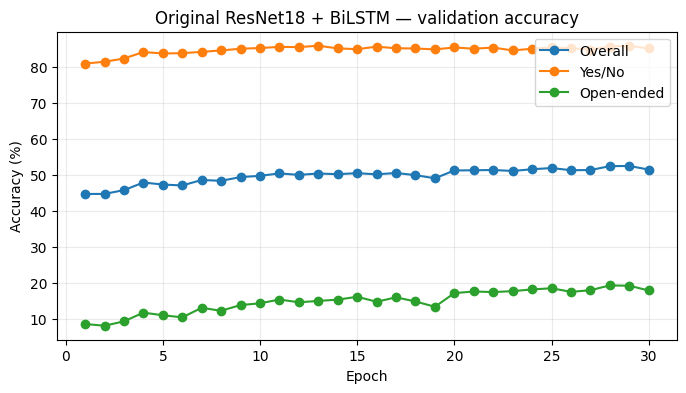

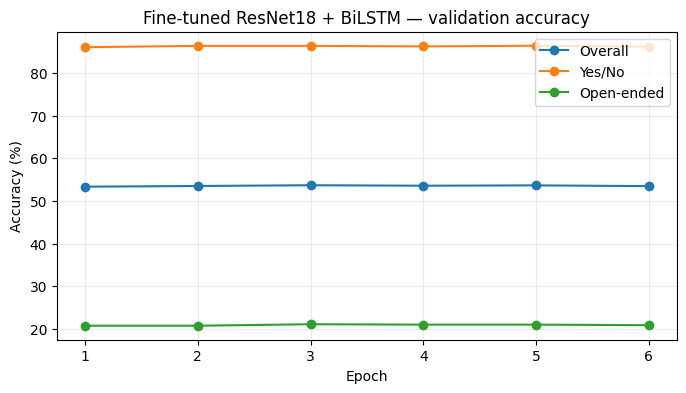

,Model,Overall (%),Yes/No (%),Open (%)
0,Image-Only CNN (fine-tuned),32.21,54.69,9.80
1,Question-Only BiLSTM (fine-tuned),48.20,85.25,11.26
2,CNN + BiLSTM (fine-tuned),54.42,86.43,22.50
3,SAN (fine-tuned),54.39,86.02,22.85
4,"QTAF-Net (fine-tuned, oracle)",54.10,85.98,22.30
5,ResNet18 + BiLSTM (original),52.61,85.98,19.34
6,ResNet18 + BiLSTM (fine-tuned),53.68,86.34,21.12


In [22]:
# Plot training history and compare validation scores with earlier baselines.
def load_history(name):
    matches = (
        glob.glob("/kaggle/working/" + name)
        + glob.glob("/kaggle/input/**/" + name, recursive=True)
    )
    return pd.read_csv(matches[0]) if matches else None

for title, filename, xcol in [
    ("Original ResNet18 + BiLSTM", "resnet18_bilstm_history.csv", "epoch"),
    ("Fine-tuned ResNet18 + BiLSTM", "resnet18_bilstm_finetune_history.csv", "finetune_epoch")
]:
    df = load_history(filename)
    if df is None:
        print("History not found:", filename)
        continue
    plt.figure(figsize=(8, 4))
    for col, label in [
        ("overall_accuracy", "Overall"), ("yes_no_accuracy", "Yes/No"),
        ("open_accuracy", "Open-ended")
    ]:
        plt.plot(df[xcol], df[col] * 100, marker="o", label=label)
    plt.title(title + " — validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()

comparison = pd.DataFrame([
    {"Model": "Image-Only CNN (fine-tuned)", "Overall (%)": 32.21, "Yes/No (%)": 54.69, "Open (%)": 9.80},
    {"Model": "Question-Only BiLSTM (fine-tuned)", "Overall (%)": 48.20, "Yes/No (%)": 85.25, "Open (%)": 11.26},
    {"Model": "CNN + BiLSTM (fine-tuned)", "Overall (%)": 54.42, "Yes/No (%)": 86.43, "Open (%)": 22.50},
    {"Model": "SAN (fine-tuned)", "Overall (%)": 54.39, "Yes/No (%)": 86.02, "Open (%)": 22.85},
    {"Model": "QTAF-Net (fine-tuned, oracle)", "Overall (%)": 54.10, "Yes/No (%)": 85.98, "Open (%)": 22.30},
    {"Model": "ResNet18 + BiLSTM (original)", "Overall (%)": 100*original_metrics["overall_accuracy"],
     "Yes/No (%)": 100*original_metrics["closed_accuracy"],
     "Open (%)": 100*original_metrics["open_accuracy"]},
    {"Model": "ResNet18 + BiLSTM (fine-tuned)", "Overall (%)": 100*finetuned_metrics["overall_accuracy"],
     "Yes/No (%)": 100*finetuned_metrics["closed_accuracy"],
     "Open (%)": 100*finetuned_metrics["open_accuracy"]},
])
display(comparison.round(2))
comparison.to_csv("/kaggle/working/resnet18_bilstm_baseline_comparison.csv", index=False)

## 15. Backup checkpoints and results

Download the ZIP and both best `.pth` files before closing Kaggle. The latest checkpoints also contain the vocabulary mappings for reproducible final evaluation.

In [23]:
# Bundle model checkpoints and result files for reproducible Kaggle downloads.
filenames = [
    "best_resnet18_bilstm.pth", "resnet18_bilstm_latest.pth", "resnet18_bilstm_history.csv",
    "best_resnet18_bilstm_finetuned.pth", "resnet18_bilstm_finetune_latest.pth",
    "resnet18_bilstm_finetune_history.csv", "resnet18_bilstm_baseline_comparison.csv"
]
zip_path = "/kaggle/working/resnet18_bilstm_experiment_backup.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in filenames:
        path = "/kaggle/working/" + filename
        if os.path.isfile(path):
            zf.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not yet available:", filename)
print("Backup ready:", zip_path)

Added: best_resnet18_bilstm.pth
Added: resnet18_bilstm_latest.pth
Added: resnet18_bilstm_history.csv
Added: best_resnet18_bilstm_finetuned.pth
Added: resnet18_bilstm_finetune_latest.pth
Added: resnet18_bilstm_finetune_history.csv
Added: resnet18_bilstm_baseline_comparison.csv
Backup ready: /kaggle/working/resnet18_bilstm_experiment_backup.zip


## 16. After training

Share **best original** and **best fine-tuned** overall, yes/no, and open-ended validation accuracies. Keep both `.pth` files and the backup ZIP. After this fifth baseline, we can create a shared final evaluation notebook for all architectures and ablation variants, using the **untouched test set**. Remember to document that these baselines use **oracle answer-type routing**; QTAF-Net additionally supports predicted routing.

**Research limitation:** The original proposal may describe pretrained ResNet18, but this experiment deliberately uses randomly initialized ResNet18 to comply with the project's strict no-pretrained rule. Describe it as **ResNet18 trained from scratch** in the final report.